In [1]:
print("Hello World")

Hello World


In [2]:
!nvidia-smi

Wed Apr 16 04:49:39 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   66C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!pip install -q kaggle

In [4]:
# Upload the kaggle.json file
from google.colab import files
print("Please upload your kaggle.json file")
files.upload()
print("File uploaded successfully!")

# Make directory named kaggle and copy kaggle.json file there.
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/

# Change the permissions of the file.
!chmod 600 ~/.kaggle/kaggle.json
print("Kaggle API configured.")

Please upload your kaggle.json file


Saving kaggle.json to kaggle.json
File uploaded successfully!
Kaggle API configured.


In [5]:
# Download the dataset (replace with the correct dataset path if needed)
!kaggle datasets download -d ucimachinelearning/deep-fake-detection-cropped-dataset
print("Dataset download initiated. This may take some time...")

Dataset URL: https://www.kaggle.com/datasets/ucimachinelearning/deep-fake-detection-cropped-dataset
License(s): CC0-1.0
Dataset download initiated. This may take some time...


In [6]:
# Unzip the downloaded dataset
!unzip -q deep-fake-detection-cropped-dataset.zip -d ./deepfake_data
print("Dataset unzipped into the 'deepfake_data' directory.")

# Optional: Remove the zip file to save space
!rm deep-fake-detection-cropped-dataset.zip

Dataset unzipped into the 'deepfake_data' directory.


In [7]:
# List the contents of the dataset directory
!ls -l ./deepfake_data

total 4
drwxr-xr-x 4 root root 4096 Apr 16 04:51 DFDC_Dataset


In [8]:
# List the contents of the DFDC_Dataset directory
!ls -l ./deepfake_data/DFDC_Dataset

total 132
drwxr-xr-x 2 root root 69632 Apr 16 04:51 Fake
drwxr-xr-x 2 root root 65536 Apr 16 04:51 Real


In [9]:
# Add this cell early in the notebook
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [10]:
import cv2 # OpenCV for video processing
import numpy as np
import os # For navigating file paths
from tqdm.notebook import tqdm # Progress bar (use tqdm.notebook in Colab)
# import G # For file operations

# --- Constants ---
VIDEO_DATA_DIR = './deepfake_data/DFDC_Dataset'
OUTPUT_DIR = './processed_sequences' # Directory to save processed frame sequences
FRAME_COUNT = 150 # Number of frames to extract per video (as per original plan)
IMG_SIZE = (112, 112) # Target image size (height, width)

# --- Create Output Directory ---
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)
    # Create subdirectories for clarity
    os.makedirs(os.path.join(OUTPUT_DIR, 'Real'))
    os.makedirs(os.path.join(OUTPUT_DIR, 'Fake'))
    print(f"Created output directory: {OUTPUT_DIR} and subdirectories.")
else:
    print(f"Output directory {OUTPUT_DIR} already exists.")

Created output directory: ./processed_sequences and subdirectories.


In [11]:
def extract_frames(video_path, frame_count, img_size):
    """
    Extracts, resizes, and pads frames from a video file.

    Args:
        video_path (str): Path to the video file.
        frame_count (int): The target number of frames.
        img_size (tuple): The target frame size (height, width).

    Returns:
        np.ndarray or None: A NumPy array of shape (frame_count, H, W, 3)
                             containing the processed frames, or None if
                             the video couldn't be opened or has 0 frames.
    """
    frames = []
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        print(f"Error: Could not open video {video_path}")
        return None

    total_frames_in_video = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames_in_video == 0:
         print(f"Warning: Video {video_path} has 0 frames.")
         cap.release()
         return None

    extracted_count = 0
    while extracted_count < frame_count:
        ret, frame = cap.read()
        if not ret:
            # Video ended before reaching frame_count
            break

        # Resize frame
        frame_resized = cv2.resize(frame, (img_size[1], img_size[0])) # cv2 uses (width, height)

        # OpenCV reads in BGR, convert to RGB
        frame_rgb = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2RGB)

        frames.append(frame_rgb)
        extracted_count += 1

    cap.release()

    # --- Padding ---
    # If fewer frames were extracted than needed, pad with the last frame
    if extracted_count == 0: # Handle cases where video had frames but reading failed early
         print(f"Warning: Could not read any frames from {video_path} despite it having {total_frames_in_video} frames.")
         return None # Or handle differently if needed

    if extracted_count < frame_count:
        last_frame = frames[-1]
        padding_needed = frame_count - extracted_count
        for _ in range(padding_needed):
            frames.append(last_frame)

    # Should now have exactly frame_count frames
    return np.array(frames) # Shape: (frame_count, H, W, 3)

In [12]:
# --- Process Videos ---

processed_count = 0
skipped_count = 0

for label in ['Real', 'Fake']:
    print(f"\nProcessing '{label}' videos...")
    input_folder = os.path.join(VIDEO_DATA_DIR, label)
    output_folder = os.path.join(OUTPUT_DIR, label)

    video_files = [f for f in os.listdir(input_folder) if os.path.isfile(os.path.join(input_folder, f)) and f.lower().endswith(('.mp4', '.avi', '.mov'))] # Basic check for video files

    if not video_files:
        print(f"Warning: No video files found in {input_folder}")
        continue

    for video_file in tqdm(video_files, desc=f"Processing {label}"):
        video_path = os.path.join(input_folder, video_file)
        output_filename = os.path.splitext(video_file)[0] + ".npy" # Save as .npy
        output_path = os.path.join(output_folder, output_filename)

        # Avoid reprocessing if file already exists
        if os.path.exists(output_path):
            # print(f"Skipping {output_path}, already processed.")
            skipped_count +=1
            continue

        # Extract frames
        frame_sequence = extract_frames(video_path, FRAME_COUNT, IMG_SIZE)

        # Save the result if successful
        if frame_sequence is not None:
            np.save(output_path, frame_sequence)
            processed_count += 1
        else:
            print(f"Skipping video {video_file} due to processing errors.")
            skipped_count += 1


print(f"\n--- Processing Complete ---")
print(f"Successfully processed and saved: {processed_count} videos.")
print(f"Skipped (already exists or error): {skipped_count} videos.")

# Verify by listing some processed files
print("\nSample processed files in Real:")
!ls -lh ./processed_sequences/Real | head -n 5

print("\nSample processed files in Fake:")
!ls -lh ./processed_sequences/Fake | head -n 5


Processing 'Real' videos...


Processing Real:   0%|          | 0/1727 [00:00<?, ?it/s]


Processing 'Fake' videos...


Processing Fake:   0%|          | 0/1566 [00:00<?, ?it/s]


--- Processing Complete ---
Successfully processed and saved: 3293 videos.
Skipped (already exists or error): 0 videos.

Sample processed files in Real:
total 9.1G
-rw-r--r-- 1 root root 5.4M Apr 16 04:52 aabqyygbaa.npy
-rw-r--r-- 1 root root 5.4M Apr 16 04:53 aajsqyyjni.npy
-rw-r--r-- 1 root root 5.4M Apr 16 04:53 aayfryxljh.npy
-rw-r--r-- 1 root root 5.4M Apr 16 04:52 abbgqbrdiz.npy

Sample processed files in Fake:
total 8.3G
-rw-r--r-- 1 root root 5.4M Apr 16 04:54 aaagqkcdis.npy
-rw-r--r-- 1 root root 5.4M Apr 16 04:54 aaaoqepxnf.npy
-rw-r--r-- 1 root root 5.4M Apr 16 04:54 aabdnomlru.npy
-rw-r--r-- 1 root root 5.4M Apr 16 04:54 aabkwhhgwv.npy


In [13]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import torchvision.transforms as transforms # Keep this import
import random # <<< ---- Add this import for random sampling

# Directory containing the processed .npy files
PROCESSED_DIR = './processed_sequences'
REAL_DIR = os.path.join(PROCESSED_DIR, 'Real')
FAKE_DIR = os.path.join(PROCESSED_DIR, 'Fake')

# --- >>> START MODIFICATION <<< ---
TARGET_COUNT_PER_CLASS = 600 # Define desired number per class

# Get list of ALL available file paths first
print("Scanning for all processed files...")
all_real_files = [os.path.join(REAL_DIR, f) for f in os.listdir(REAL_DIR) if f.endswith('.npy')]
all_fake_files = [os.path.join(FAKE_DIR, f) for f in os.listdir(FAKE_DIR) if f.endswith('.npy')]

print(f"Found {len(all_real_files)} total real sequences.")
print(f"Found {len(all_fake_files)} total fake sequences.")

# Seed random sampling for reproducibility (optional but good practice)
random.seed(42)

# Check if we have enough files before sampling
if len(all_real_files) < TARGET_COUNT_PER_CLASS:
    print(f"Warning: Only found {len(all_real_files)} real files, but requested {TARGET_COUNT_PER_CLASS}. Using all available real files.")
    real_files_subset = all_real_files
else:
    # Randomly sample the target number of real files
    real_files_subset = random.sample(all_real_files, TARGET_COUNT_PER_CLASS)
    print(f"Randomly selected {len(real_files_subset)} real files.")

if len(all_fake_files) < TARGET_COUNT_PER_CLASS:
    print(f"Warning: Only found {len(all_fake_files)} fake files, but requested {TARGET_COUNT_PER_CLASS}. Using all available fake files.")
    fake_files_subset = all_fake_files
else:
    # Randomly sample the target number of fake files
    fake_files_subset = random.sample(all_fake_files, TARGET_COUNT_PER_CLASS)
    print(f"Randomly selected {len(fake_files_subset)} fake files.")


# Create labels for the SELECTED SUBSET
real_labels = [0] * len(real_files_subset)
fake_labels = [1] * len(fake_files_subset)

# Combine the SUBSET lists
all_files = real_files_subset + fake_files_subset
all_labels = real_labels + fake_labels

# --- Optional but recommended: Shuffle the combined list ---
# This ensures real/fake samples are mixed before splitting,
# although train_test_split with stratify also helps.
print("\nShuffling the combined subset...")
combined = list(zip(all_files, all_labels))
random.shuffle(combined)
all_files, all_labels = zip(*combined)
# Convert back from tuples to lists if needed later (train_test_split handles iterables)
all_files = list(all_files)
all_labels = list(all_labels)
print("Shuffling complete.")
# --- End Optional Shuffle ---


print(f"\nUsing subset of {len(real_files_subset)} real sequences.")
print(f"Using subset of {len(fake_files_subset)} fake sequences.")
print(f"Total sequences selected for use: {len(all_files)}") # Should be <= 1200
# --- >>> END MODIFICATION <<< ---

Scanning for all processed files...
Found 1727 total real sequences.
Found 1566 total fake sequences.
Randomly selected 600 real files.
Randomly selected 600 fake files.

Shuffling the combined subset...
Shuffling complete.

Using subset of 600 real sequences.
Using subset of 600 fake sequences.
Total sequences selected for use: 1200


In [14]:
# Split the data (e.g., 80% train, 20% validation)
TRAIN_SPLIT = 0.80
RANDOM_SEED = 42 # for reproducibility

train_files, val_files, train_labels, val_labels = train_test_split(
    all_files, all_labels, train_size=TRAIN_SPLIT, random_state=RANDOM_SEED, stratify=all_labels
)

print(f"Training samples: {len(train_files)}")
print(f"Validation samples: {len(val_files)}")

# Verify stratification (optional)
train_real_count = sum(1 for label in train_labels if label == 0)
train_fake_count = len(train_labels) - train_real_count
val_real_count = sum(1 for label in val_labels if label == 0)
val_fake_count = len(val_labels) - val_real_count

print(f"Train split: {train_real_count} Real / {train_fake_count} Fake ({train_fake_count/(train_real_count+train_fake_count)*100:.1f}% Fake)")
print(f"Validation split: {val_real_count} Real / {val_fake_count} Fake ({val_fake_count/(val_real_count+val_fake_count)*100:.1f}% Fake)")

Training samples: 960
Validation samples: 240
Train split: 480 Real / 480 Fake (50.0% Fake)
Validation split: 120 Real / 120 Fake (50.0% Fake)


In [15]:
class DeepfakeSequenceDataset(Dataset):
    """
    Custom Dataset for loading deepfake frame sequences stored as .npy files.
    """
    def __init__(self, file_paths, labels, transform=None):
        """
        Args:
            file_paths (list): List of paths to .npy files.
            labels (list): List of corresponding labels (0 or 1).
            transform (callable, optional): Optional transform to be applied on a sample.
        """
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        # Load the .npy file (sequence of frames)
        file_path = self.file_paths[idx]
        sequence = np.load(file_path) # Shape: (N, H, W, C) = (150, 112, 112, 3)

        # Convert to float and scale pixels to [0, 1]
        sequence = sequence.astype(np.float32) / 255.0

        # Convert NumPy array to PyTorch tensor
        sequence_tensor = torch.from_numpy(sequence)

        # ** IMPORTANT: Permute dimensions **
        # PyTorch expects (N, C, H, W) or (C, N, H, W) depending on model.
        # For ResNet feature extraction per frame, followed by LSTM,
        # we process frame-by-frame, needing (C, H, W) per frame.
        # DataLoader will batch this to (B, N, C, H, W).
        # Let's keep the output shape (N, C, H, W) for now.
        sequence_tensor = sequence_tensor.permute(0, 3, 1, 2) # (150, 3, 112, 112)

        # Get the label
        label = self.labels[idx]
        label_tensor = torch.tensor(label, dtype=torch.long) # Use long for CrossEntropyLoss

        # Apply transforms if any (e.g., normalization)
        if self.transform:
             # Apply transform to each frame in the sequence individually? Or the whole sequence?
             # For normalization, it's per frame. Let's assume transform handles a (C, H, W) tensor.
             # We might need a custom transform or apply it differently.
             # For now, let's skip additional transforms here and handle normalization in the model if needed,
             # or stick to the simple [0, 1] scaling above.
             # sequence_tensor = self.transform(sequence_tensor) # Placeholder
             pass


        return sequence_tensor, label_tensor

# Example usage (optional, for verification)
# test_dataset = DeepfakeSequenceDataset([train_files[0]], [train_labels[0]])
# sample_sequence, sample_label = test_dataset[0]
# print("Sample sequence shape:", sample_sequence.shape) # Should be [150, 3, 112, 112]
# print("Sample label:", sample_label)

In [16]:
# --- Create DataLoaders ---
BATCH_SIZE = 2 # Adjust based on GPU memory (4 was mentioned in the original text, start small)
NUM_WORKERS = 2 # Number of parallel workers for loading data (usually 2 or 4 in Colab)

# Create Dataset instances
# We can add specific transforms later if needed (e.g., for data augmentation)
train_dataset = DeepfakeSequenceDataset(train_files, train_labels)
val_dataset = DeepfakeSequenceDataset(val_files, val_labels)

# Create DataLoader instances
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True, # Shuffle training data
    num_workers=NUM_WORKERS,
    pin_memory=True # Speeds up data transfer to GPU if possible
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # No need to shuffle validation data
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"\nDataLoaders created.")
print(f"Train batches per epoch: {len(train_loader)}")
print(f"Validation batches per epoch: {len(val_loader)}")

# --- Optional: Verify one batch ---
print("\nVerifying one batch from train_loader:")
try:
    # Use iter and next to get one batch without running the whole loader
    data_iter = iter(train_loader)
    sequences_batch, labels_batch = next(data_iter)
    print("Batch sequence shape:", sequences_batch.shape) # Should be [BATCH_SIZE, 150, 3, 112, 112]
    print("Batch labels shape:", labels_batch.shape)     # Should be [BATCH_SIZE]
    print("Batch sequence dtype:", sequences_batch.dtype) # Should be torch.float32
    print("Batch labels dtype:", labels_batch.dtype)     # Should be torch.int64 (long)
except Exception as e:
    print(f"Error verifying batch: {e}")
    print("Check num_workers setting or dataset implementation.")


DataLoaders created.
Train batches per epoch: 480
Validation batches per epoch: 120

Verifying one batch from train_loader:
Batch sequence shape: torch.Size([2, 150, 3, 112, 112])
Batch labels shape: torch.Size([2])
Batch sequence dtype: torch.float32
Batch labels dtype: torch.int64


In [17]:
import torch
import torch.nn as nn
import torchvision.models as models

# --- Device Configuration ---
# Set device to GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- Model Definition ---
class DeepfakeDetector(nn.Module):
    def __init__(self, num_classes=2, lstm_hidden_size=2048, num_lstm_layers=1, lstm_dropout=0.4):
        super(DeepfakeDetector, self).__init__()

        # 1. ResNeXt Feature Extractor
        # Load pre-trained ResNeXt-50
        resnext = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V2)

        # Remove the final fully connected layer (the classifier)
        # Modules are named, we access all layers EXCEPT the last one ('fc')
        modules = list(resnext.children())[:-1]
        self.resnext_features = nn.Sequential(*modules)

        # Output feature dimension from ResNeXt (after avgpool) is 2048
        cnn_feature_size = 2048

        # Optional: Freeze some layers of ResNeXt if desired (we'll fine-tune all for now)
        # for param in self.resnext_features.parameters():
        #     param.requires_grad = True # Fine-tune all layers

        # 2. LSTM for Sequence Processing
        self.lstm = nn.LSTM(
            input_size=cnn_feature_size,
            hidden_size=lstm_hidden_size,
            num_layers=num_lstm_layers,
            batch_first=True, # Input shape: (batch, seq_len, features)
            dropout=lstm_dropout if num_lstm_layers > 1 else 0 # Dropout only between LSTM layers
        )

        # 3. Classifier Head
        # Using AdaptiveAvgPool1d to summarize LSTM sequence output
        self.pool = nn.AdaptiveAvgPool1d(1) # Pool across the sequence dimension

        # Dropout layer (as mentioned 0.4 chance)
        self.dropout = nn.Dropout(lstm_dropout)

        # LeakyReLU activation (apply before final linear layer)
        self.relu = nn.LeakyReLU() # Or other activation if preferred

        # Final Linear layer for classification
        self.fc = nn.Linear(lstm_hidden_size, num_classes)


    def forward(self, x):
        # x shape: (B, N, C, H, W) -> (batch_size, 150, 3, 112, 112)
        batch_size, seq_length, C, H, W = x.shape

        # --- Reshape for CNN ---
        # Treat sequence dimension N as part of the batch for CNN processing
        x_reshaped = x.view(batch_size * seq_length, C, H, W)

        # --- Get CNN features ---
        # Pass through ResNeXt feature extractor
        features = self.resnext_features(x_reshaped) # Shape: (B*N, 2048, 1, 1)

        # Remove spatial dimensions (1x1)
        features = features.view(batch_size * seq_length, -1) # Shape: (B*N, 2048)

        # --- Reshape back for LSTM ---
        # Group features back into sequences
        features_seq = features.view(batch_size, seq_length, -1) # Shape: (B, N, 2048)

        # --- LSTM processing ---
        # Pass the sequence through LSTM
        # lstm_out shape: (B, N, lstm_hidden_size)
        # hidden shape: (num_layers, B, lstm_hidden_size)
        # cell shape: (num_layers, B, lstm_hidden_size)
        lstm_out, (hidden, cell) = self.lstm(features_seq)

        # --- Summarize Sequence ---
        # We need to pool across the sequence length (N)
        # AdaptiveAvgPool1d expects (B, C, N), so permute lstm_out
        lstm_out_permuted = lstm_out.permute(0, 2, 1) # Shape: (B, lstm_hidden_size, N)
        pooled_out = self.pool(lstm_out_permuted) # Shape: (B, lstm_hidden_size, 1)

        # Remove the last dimension (resulting from pooling)
        pooled_out = pooled_out.squeeze(-1) # Shape: (B, lstm_hidden_size)

        # --- Classification Head ---
        # Apply Dropout
        out = self.dropout(pooled_out)

        # Apply activation (LeakyReLU)
        out = self.relu(out)

        # Apply final linear layer
        logits = self.fc(out) # Shape: (B, num_classes) = (B, 2)

        return logits


# --- Instantiate the Model and Move to Device ---
model = DeepfakeDetector().to(device)

# --- Optional: Print Model Summary ---
# Install torchinfo if you don't have it: !pip install -q torchinfo
try:
    from torchinfo import summary
    # Provide dummy input shape (Batch Size, Sequence Length, Channels, Height, Width)
    # Use a smaller batch size for summary to avoid memory issues
    summary(model, input_size=(2, 150, 3, 112, 112), device=str(device))
except ImportError:
    print("torchinfo not found. Skipping model summary.")
    print(model) # Print basic model structure

Using device: cuda


Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth
100%|██████████| 95.8M/95.8M [00:02<00:00, 40.1MB/s]


torchinfo not found. Skipping model summary.
DeepfakeDetector(
  (resnext_features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(128, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu):

In [18]:
import torch.optim as optim
import time # To time training epochs
import copy # To save the best model state

# --- Loss Function ---
# CrossEntropyLoss combines LogSoftmax and NLLLoss, suitable for classification
criterion = nn.CrossEntropyLoss()

# --- Optimizer ---
# Adam optimizer as specified
optimizer = optim.Adam(
    model.parameters(),
    lr=1e-5,          # Learning rate from the description
    weight_decay=1e-3 # Weight decay from the description
)

# --- Learning Rate Scheduler (Optional but often helpful) ---
# Example: Reduce learning rate if validation loss stops improving
# scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.5, verbose=True)

print("Loss function and optimizer defined.")

Loss function and optimizer defined.


In [19]:
from tqdm.notebook import tqdm
# --- Training Parameters ---
NUM_EPOCHS = 10 # Start with a small number (e.g., 10-20) and increase later
MODEL_SAVE_PATH = '/content/drive/MyDrive/Colab Notebooks/Deepfake_Project/deepfake_detector_best.pth' # Path to save the best model

# --- Training History Storage ---
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

best_val_acc = 0.0 # Keep track of the best validation accuracy

# --- Training Loop ---
print("Starting Training...")
start_time = time.time()

for epoch in range(NUM_EPOCHS):
    epoch_start_time = time.time()
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 10)

    # --- Training Phase ---
    model.train() # Set model to training mode
    running_loss = 0.0
    running_corrects = 0
    total_train_samples = 0

    # Iterate over data.
    for i, (sequences, labels) in enumerate(tqdm(train_loader, desc="Training")):
        sequences = sequences.to(device)
        labels = labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(sequences)
        _, preds = torch.max(outputs, 1) # Get the class prediction (index of max logit)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * sequences.size(0)
        running_corrects += torch.sum(preds == labels.data)
        total_train_samples += sequences.size(0)

        # Optional: Print progress within epoch
        # if (i + 1) % 100 == 0: # Print every 100 batches
        #    print(f"  Batch {i+1}/{len(train_loader)} - Train Loss: {loss.item():.4f}")


    epoch_train_loss = running_loss / total_train_samples
    epoch_train_acc = running_corrects.double() / total_train_samples
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc.item()) # Store as float

    print(f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f}")


    # --- Validation Phase ---
    model.eval() # Set model to evaluate mode
    running_loss = 0.0
    running_corrects = 0
    total_val_samples = 0

    # Iterate over validation data.
    with torch.no_grad(): # No gradients needed for validation
        for sequences, labels in tqdm(val_loader, desc="Validation"):
            sequences = sequences.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(sequences)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            # Statistics
            running_loss += loss.item() * sequences.size(0)
            running_corrects += torch.sum(preds == labels.data)
            total_val_samples += sequences.size(0)

    epoch_val_loss = running_loss / total_val_samples
    epoch_val_acc = running_corrects.double() / total_val_samples
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc.item()) # Store as float

    print(f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

    # Optional: Step the learning rate scheduler if using one
    # scheduler.step(epoch_val_loss)

    # --- Save Best Model ---
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        # Save the model state dictionary
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(best_model_wts, MODEL_SAVE_PATH)
        print(f"*** Best model saved to {MODEL_SAVE_PATH} (Val Acc: {best_val_acc:.4f}) ***")

    epoch_time_elapsed = time.time() - epoch_start_time
    print(f"Epoch complete in {epoch_time_elapsed // 60:.0f}m {epoch_time_elapsed % 60:.0f}s")


# --- End of Training ---
time_elapsed = time.time() - start_time
print(f"\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
print(f"Best Validation Accuracy: {best_val_acc:.4f}")

# Load best model weights for subsequent evaluation
model.load_state_dict(torch.load(MODEL_SAVE_PATH))
print("Loaded best model weights for evaluation.")

Starting Training...

Epoch 1/10
----------


Training:   0%|          | 0/480 [00:00<?, ?it/s]

Train Loss: 0.6816 Acc: 0.5760


Validation:   0%|          | 0/120 [00:00<?, ?it/s]

Val Loss: 0.6429 Acc: 0.6708
*** Best model saved to /content/drive/MyDrive/Colab Notebooks/Deepfake_Project/deepfake_detector_best.pth (Val Acc: 0.6708) ***
Epoch complete in 11m 12s

Epoch 2/10
----------


Training:   0%|          | 0/480 [00:00<?, ?it/s]

... (31 outputs left out)

Training:   0%|          | 0/480 [00:00<?, ?it/s]

Train Loss: 0.1405 Acc: 0.9458


Validation:   0%|          | 0/120 [00:00<?, ?it/s]

Val Loss: 0.5564 Acc: 0.8083
Epoch complete in 11m 12s

Training complete in 112m 3s
Best Validation Accuracy: 0.8333
Loaded best model weights for evaluation.


In [20]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Ensure model is on the correct device and in evaluation mode
# (Should already be the case from the end of the training cell, but good practice)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# Lists to store true labels and predictions
all_labels = []
all_preds = []
all_probs = [] # Store probabilities for AUC

print("Preparing for evaluation...")

Preparing for evaluation...


In [21]:
# --- Evaluation Loop ---
with torch.no_grad(): # Disable gradient calculations
    for sequences, labels in tqdm(val_loader, desc="Evaluating on Validation Set"):
        sequences = sequences.to(device)
        labels = labels.to(device) # True labels

        # Get model outputs (logits)
        outputs = model(sequences)

        # Get probabilities (for AUC) using Softmax
        probs = torch.softmax(outputs, dim=1)
        # Get predicted class (0 or 1)
        _, preds = torch.max(outputs, 1)

        # Append batch results to lists (move to CPU for sklearn)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs[:, 1].cpu().numpy()) # Probability of the 'Fake' class (class 1)

print("Evaluation loop complete.")

Evaluating on Validation Set:   0%|          | 0/120 [00:00<?, ?it/s]

Evaluation loop complete.



--- Validation Set Evaluation Metrics (1 Epoch Model) ---
Accuracy:  0.8333
Precision (Fake): 0.8226
Recall (Fake):    0.8500
F1-Score (Fake):  0.8361
AUC:       0.9034


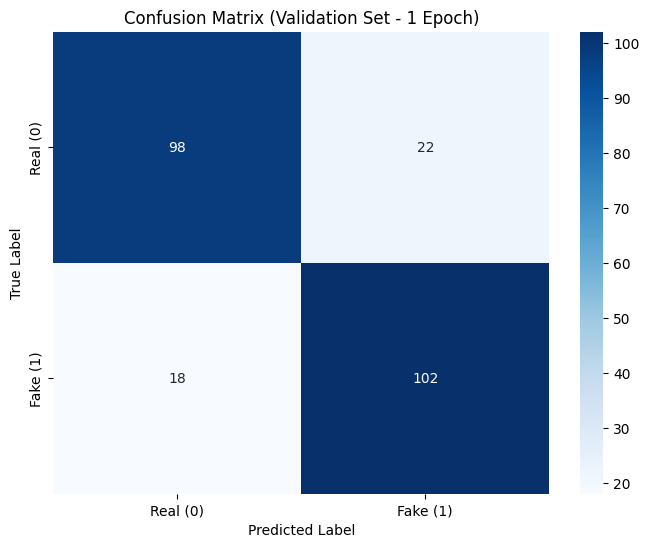

In [22]:
# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

# Calculate Metrics
accuracy = accuracy_score(all_labels, all_preds)
# Use pos_label=1 for Fake class metrics, zero_division=0 prevents warnings if a class isn't predicted
precision = precision_score(all_labels, all_preds, pos_label=1, zero_division=0)
recall = recall_score(all_labels, all_preds, pos_label=1, zero_division=0)
f1 = f1_score(all_labels, all_preds, pos_label=1, zero_division=0)
try:
    auc = roc_auc_score(all_labels, all_probs) # AUC needs probabilities
except ValueError as e:
    auc = f"Cannot calculate AUC: {e}" # Handle cases where only one class might be present/predicted in rare scenarios

print("\n--- Validation Set Evaluation Metrics (1 Epoch Model) ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision (Fake): {precision:.4f}")
print(f"Recall (Fake):    {recall:.4f}")
print(f"F1-Score (Fake):  {f1:.4f}")
print(f"AUC:       {auc if isinstance(auc, str) else f'{auc:.4f}'}") # Print AUC score or error message


# Calculate and Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Real (0)', 'Fake (1)'],
            yticklabels=['Real (0)', 'Fake (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Validation Set - 1 Epoch)')
plt.show()

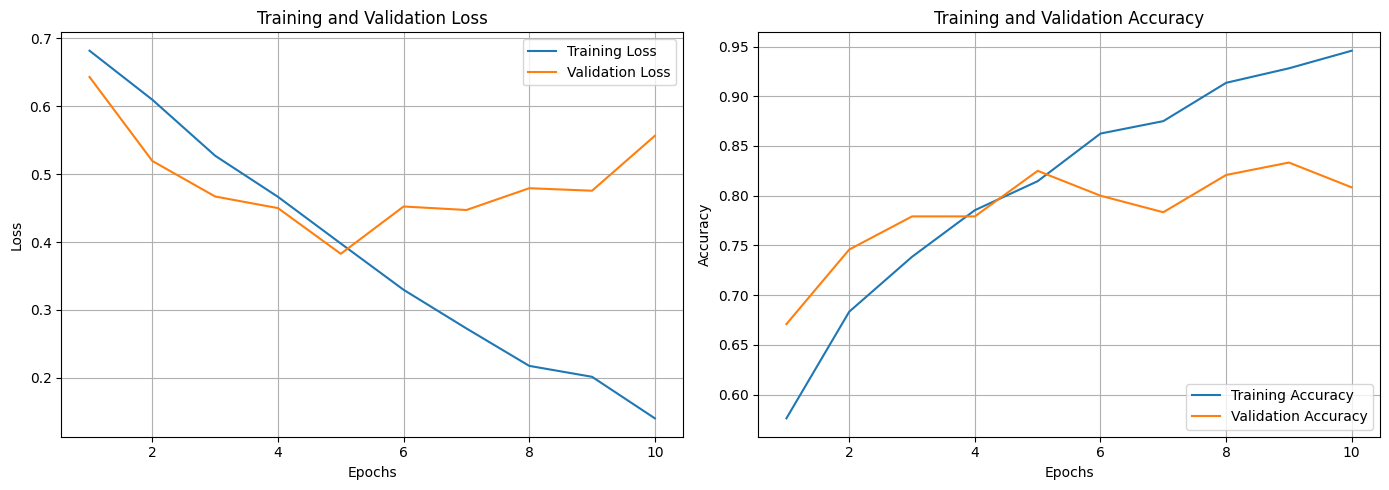

In [27]:
import matplotlib.pyplot as plt

# Ensure the 'history' dictionary from the training loop is available
if 'history' in locals():
    epochs_range = range(1, NUM_EPOCHS + 1) # NUM_EPOCHS should be 10 here

    plt.figure(figsize=(14, 5))

    # Plot Training & Validation Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Training Loss')
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend(loc='upper right')
    plt.grid(True)

    # Plot Training & Validation Accuracy
    plt.subplot(1, 2, 2)
    # Ensure accuracy values are floats for plotting if they came from tensors
    train_acc_plot = [acc.item() if isinstance(acc, torch.Tensor) else acc for acc in history['train_acc']]
    val_acc_plot = [acc.item() if isinstance(acc, torch.Tensor) else acc for acc in history['val_acc']]
    plt.plot(epochs_range, train_acc_plot, label='Training Accuracy')
    plt.plot(epochs_range, val_acc_plot, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("Error: 'history' dictionary not found. Please ensure the training loop cell was run completely.")

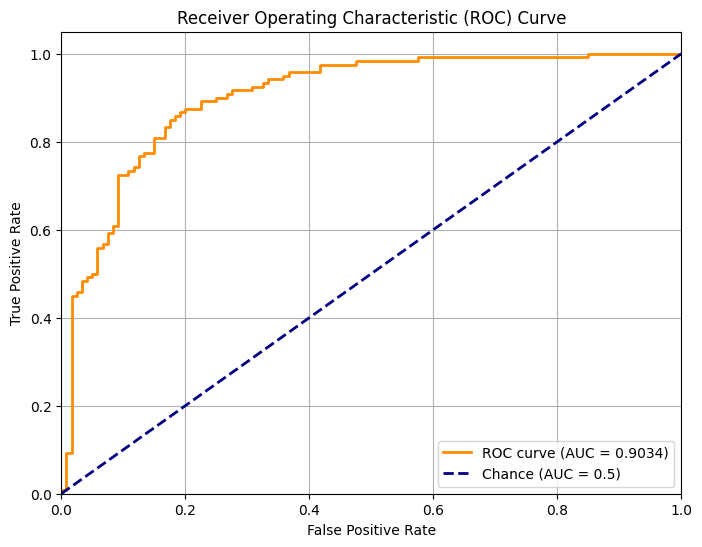

In [28]:
from sklearn.metrics import roc_curve, auc as sklearn_auc # Rename auc to avoid conflict

# Ensure 'all_labels' and 'all_probs' (probabilities of class 1) are available from Phase 6
if 'all_labels' in locals() and 'all_probs' in locals():
    fpr, tpr, thresholds = roc_curve(all_labels, all_probs, pos_label=1)
    roc_auc = sklearn_auc(fpr, tpr) # Calculate AUC using sklearn

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Chance (AUC = 0.5)')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
else:
    print("Error: 'all_labels' or 'all_probs' not found. Please ensure the Phase 6 evaluation cell was run.")

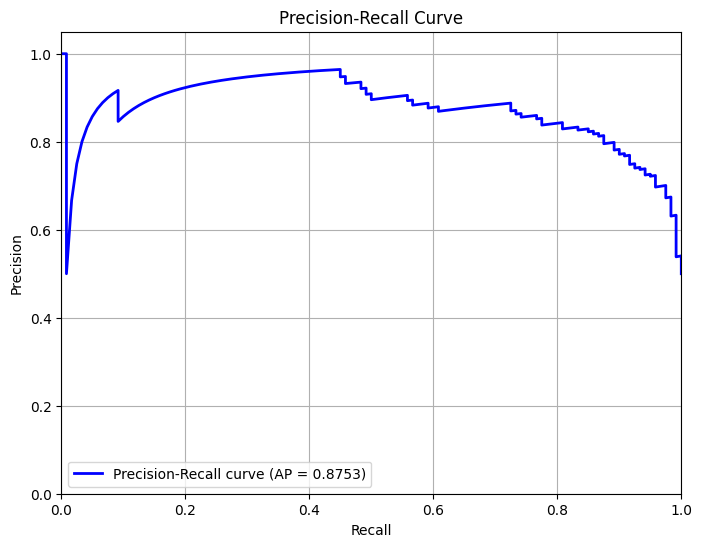

In [29]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Ensure 'all_labels' and 'all_probs' are available from Phase 6
if 'all_labels' in locals() and 'all_probs' in locals():
    precision_vals, recall_vals, _ = precision_recall_curve(all_labels, all_probs, pos_label=1)
    avg_precision = average_precision_score(all_labels, all_probs, pos_label=1)

    plt.figure(figsize=(8, 6))
    plt.plot(recall_vals, precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {avg_precision:.4f})')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.ylim([0.0, 1.05])
    plt.xlim([0.0, 1.0])
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.grid(True)
    plt.show()
else:
     print("Error: 'all_labels' or 'all_probs' not found. Please ensure the Phase 6 evaluation cell was run.")

In [30]:
from sklearn.metrics import classification_report

# Ensure 'all_labels' and 'all_preds' are available from Phase 6 evaluation
if 'all_labels' in locals() and 'all_preds' in locals():
    # Assuming 0=Real, 1=Fake
    target_names = ['Real (Class 0)', 'Fake (Class 1)']
    report = classification_report(all_labels, all_preds, target_names=target_names, digits=4)
    print("\n--- Classification Report ---")
    print(report)
else:
    print("Error: 'all_labels' or 'all_preds' not found. Please ensure the Phase 6 evaluation cell was run.")


--- Classification Report ---
                precision    recall  f1-score   support

Real (Class 0)     0.8448    0.8167    0.8305       120
Fake (Class 1)     0.8226    0.8500    0.8361       120

      accuracy                         0.8333       240
     macro avg     0.8337    0.8333    0.8333       240
  weighted avg     0.8337    0.8333    0.8333       240



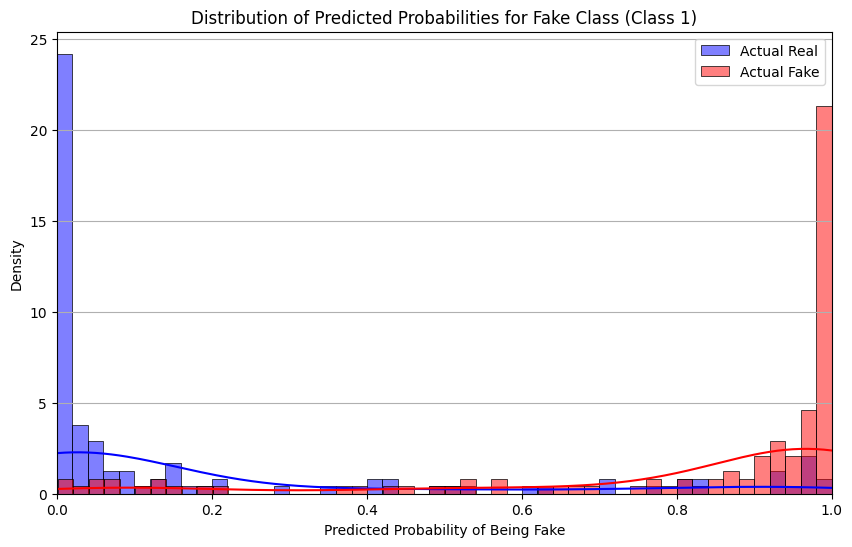

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure 'all_labels' and 'all_probs' (probabilities of class 1 - Fake) are available
if 'all_labels' in locals() and 'all_probs' in locals():
    # Separate probabilities for actual real and actual fake samples
    probs_real = all_probs[all_labels == 0]
    probs_fake = all_probs[all_labels == 1]

    plt.figure(figsize=(10, 6))
    # Plot histograms using seaborn
    sns.histplot(probs_real, color="blue", label='Actual Real', kde=True, stat="density", linewidth=0.5, bins=50)
    sns.histplot(probs_fake, color="red", label='Actual Fake', kde=True, stat="density", linewidth=0.5, bins=50)

    plt.title('Distribution of Predicted Probabilities for Fake Class (Class 1)')
    plt.xlabel('Predicted Probability of Being Fake')
    plt.ylabel('Density')
    plt.legend()
    plt.grid(True, axis='y')
    plt.xlim(0, 1)
    plt.show()
else:
    print("Error: 'all_labels' or 'all_probs' not found. Please ensure the Phase 6 evaluation cell was run.")

In [35]:
import os
import random

# --- Ensure the list of used .npy files ('all_files') is available ---
# This variable should exist if you ran the cells sequentially.
# If you restarted the runtime, you might need to re-run the cell
# from Phase 3, Section 1 (the modified one with random.sample)
# to regenerate the 'all_files' list based on the same seed.
if 'all_files' not in locals() or not all_files:
    print("Error: The list 'all_files' (containing used .npy paths) is not available.")
    print("Please re-run the modified cell from Phase 3, Section 1 first.")
    # You might want to stop execution here if 'all_files' is missing
    raise NameError("Variable 'all_files' not defined. Cannot find unused videos.")
else:
    print(f"Found the list of {len(all_files)} used .npy files.")

    # --- Get the base filenames (without extension) of the used files ---
    # Example: './processed_sequences/Real/abcde.npy' -> 'abcde'
    used_basenames = set()
    for npy_path in all_files:
        basename = os.path.splitext(os.path.basename(npy_path))[0]
        used_basenames.add(basename)
    print(f"Identified {len(used_basenames)} unique used basenames.")

    # --- Scan the ORIGINAL video directories ---
    VIDEO_DATA_DIR = './deepfake_data/DFDC_Dataset' # Original video location
    all_original_videos = []
    possible_extensions = ('.mp4', '.avi', '.mov', '.mkv') # Add others if needed

    print(f"Scanning original video directory: {VIDEO_DATA_DIR}")
    for label_dir in ['Real', 'Fake']:
        current_dir = os.path.join(VIDEO_DATA_DIR, label_dir)
        if os.path.isdir(current_dir):
            for filename in os.listdir(current_dir):
                if filename.lower().endswith(possible_extensions):
                    # Get original video path and its basename
                    original_path = os.path.join(current_dir, filename)
                    original_basename = os.path.splitext(filename)[0]

                    # --- Check if this video was used ---
                    if original_basename not in used_basenames:
                        all_original_videos.append(original_path)
        else:
            print(f"Warning: Directory not found {current_dir}")

    print(f"Found {len(all_original_videos)} original video files that were NOT used for training/validation.")

    # --- Select one unused video for testing ---
    if not all_original_videos:
        print("\nError: Could not find any unused video files for testing!")
        test_video_path = None # Set to None if none found
    else:
        # Select a random one from the unused list
        test_video_path = random.choice(all_original_videos)
        print(f"\nSelected unused video for testing: {test_video_path}")

        # Optional: You can manually set a specific unused video if you prefer
        # test_video_path = all_original_videos[0] # Or pick based on index

Found the list of 1200 used .npy files.
Identified 1200 unique used basenames.
Scanning original video directory: ./deepfake_data/DFDC_Dataset
Found 2093 original video files that were NOT used for training/validation.

Selected unused video for testing: ./deepfake_data/DFDC_Dataset/Fake/aonaupzilc.mp4


In [25]:
import torch
import cv2 # Make sure cv2 is imported
import numpy as np # Make sure numpy is imported

# Ensure the extract_frames function from Phase 2 is defined in your notebook environment
# If not, re-run the cell where it was defined.

def predict_deepfake(video_path, model, device, frame_count, img_size):
    """
    Predicts if a single video is Real or Fake using the trained model.

    Args:
        video_path (str): Path to the video file.
        model (nn.Module): The trained PyTorch model (already loaded with weights).
        device (torch.device): The device (CPU or CUDA).
        frame_count (int): The target number of frames (e.g., 150).
        img_size (tuple): The target frame size (e.g., (112, 112)).

    Returns:
        tuple: (predicted_label_str, confidence_score) or (None, None) if error.
    """
    # --- 1. Preprocessing ---
    # Use the same frame extraction logic as before
    try:
        frame_sequence = extract_frames(video_path, frame_count, img_size)
        if frame_sequence is None:
            print(f"Error: Could not extract frames from {video_path}")
            return None, None
    except Exception as e:
        print(f"Error during frame extraction for {video_path}: {e}")
        return None, None

    # Convert to float, scale pixels, convert to tensor, permute dimensions
    sequence_tensor = torch.from_numpy(frame_sequence.astype(np.float32) / 255.0)
    sequence_tensor = sequence_tensor.permute(0, 3, 1, 2) # (N, C, H, W)

    # Add batch dimension -> (1, N, C, H, W)
    sequence_tensor = sequence_tensor.unsqueeze(0)

    # Move tensor to the correct device
    sequence_tensor = sequence_tensor.to(device)

    # --- 2. Inference ---
    model.eval() # Ensure model is in evaluation mode
    with torch.no_grad(): # Disable gradient calculation
        outputs = model(sequence_tensor) # Get raw logits
        probs = torch.softmax(outputs, dim=1) # Get probabilities
        confidence, predicted_idx = torch.max(probs, 1) # Get confidence and index

    # --- 3. Post-processing ---
    predicted_idx = predicted_idx.item() # Get index as integer
    confidence_score = confidence.item() # Get confidence as float

    # Map index to label string (assuming 0=Real, 1=Fake)
    label_map = {0: 'Real', 1: 'Fake'}
    predicted_label_str = label_map.get(predicted_idx, "Unknown")

    return predicted_label_str, confidence_score

print("Prediction function defined.")

Prediction function defined.


In [36]:
# --- Prediction Cell (Phase 7, Step 3) ---
# (Assumes the cell above was run and 'test_video_path' is set)

if test_video_path is not None:
    # Ensure your trained 'model' object, 'device', FRAME_COUNT, and IMG_SIZE are available
    if 'model' in locals() and 'device' in locals():
        predicted_label, confidence = predict_deepfake(
            test_video_path,
            model,
            device,
            FRAME_COUNT, # Should be 150
            IMG_SIZE     # Should be (112, 112)
        )

        if predicted_label is not None:
            print(f"\n--- Prediction Result ---")
            print(f"Video: {test_video_path}")
            print(f"Predicted Label: {predicted_label}")
            print(f"Confidence: {confidence:.4f}")
        else:
            print(f"Could not get prediction for {test_video_path}.")
    else:
        print("Error: Model or device not defined. Make sure previous cells were run.")
else:
    print("Skipping prediction as no unused test video was found.")


--- Prediction Result ---
Video: ./deepfake_data/DFDC_Dataset/Fake/aonaupzilc.mp4
Predicted Label: Fake
Confidence: 0.9974


Displaying sample frames from validation set...


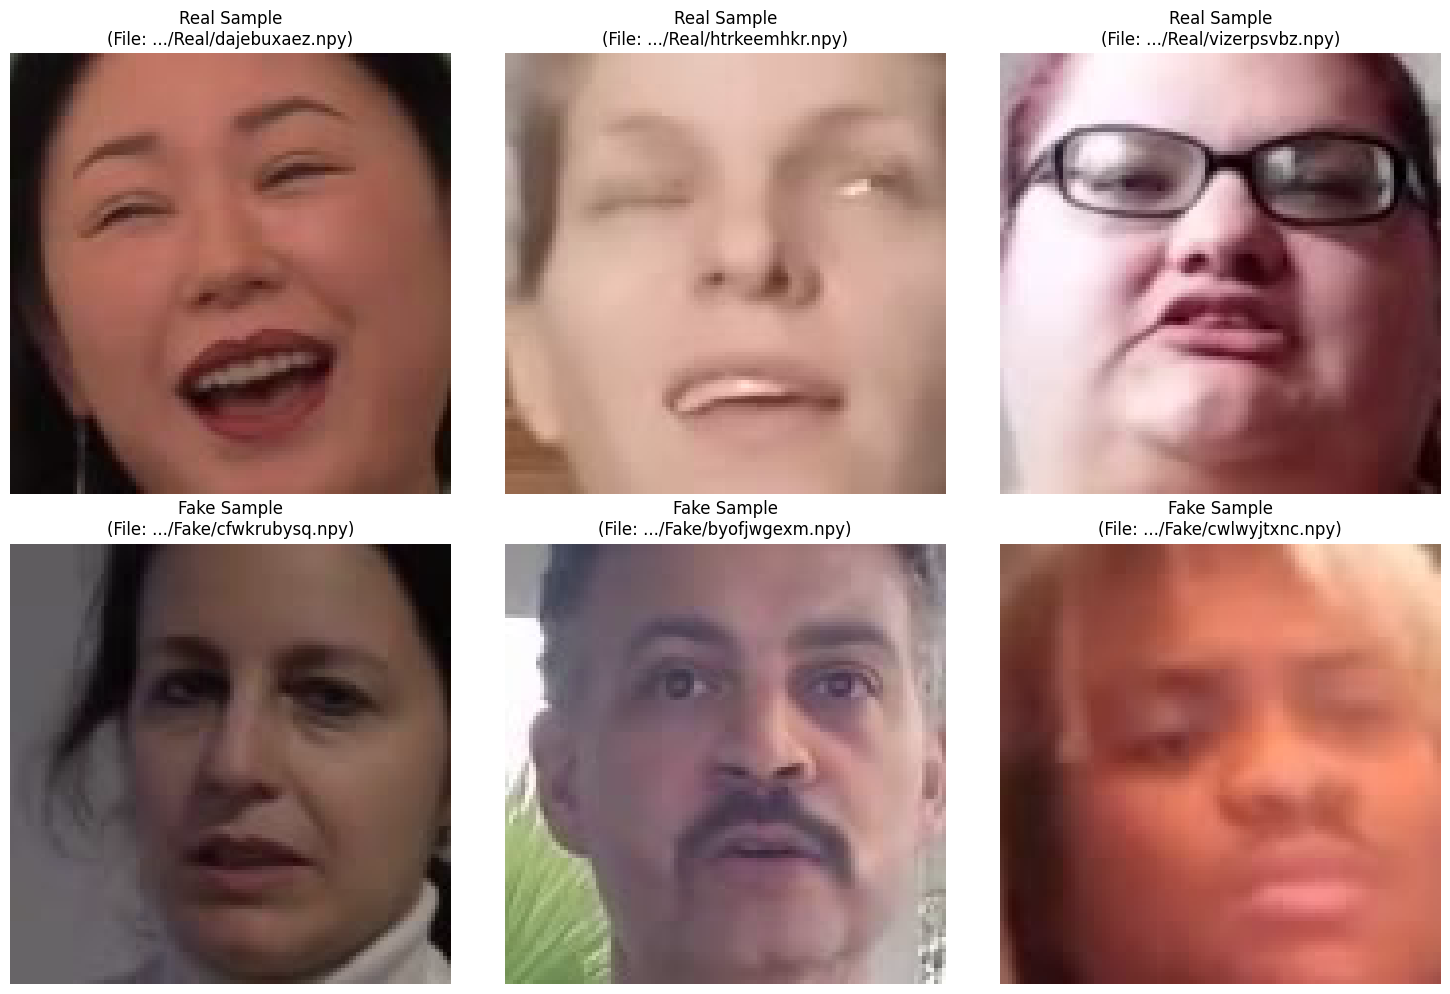

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Ensure 'val_files' and 'val_labels' (or train_files/train_labels) are available
if 'val_files' in locals() and 'val_labels' in locals():
    num_samples_to_show = 3 # Show 3 real and 3 fake

    real_indices = [i for i, label in enumerate(val_labels) if label == 0]
    fake_indices = [i for i, label in enumerate(val_labels) if label == 1]

    # Select random samples
    sample_real_indices = random.sample(real_indices, min(num_samples_to_show, len(real_indices)))
    sample_fake_indices = random.sample(fake_indices, min(num_samples_to_show, len(fake_indices)))

    plt.figure(figsize=(15, 10))
    plot_idx = 1

    print("Displaying sample frames from validation set...")

    # Display Real samples
    for i in sample_real_indices:
        npy_path = val_files[i]
        try:
            sequence = np.load(npy_path) # Shape (N, H, W, C)
            # Display the middle frame (or first frame)
            frame_to_show = sequence[sequence.shape[0] // 2] # Middle frame
            # Need to rescale from [0,1] if normalized earlier, or just display if saved as uint8
            # Assuming it was saved as uint8 [0-255] from Phase 2:
            # frame_to_show = (frame_to_show * 255).astype(np.uint8) # If normalized to [0,1] before saving

            plt.subplot(2, num_samples_to_show, plot_idx)
            plt.imshow(frame_to_show)
            plt.title(f"Real Sample\n(File: ...{npy_path[-20:]})") # Show partial filename
            plt.axis('off')
            plot_idx += 1
        except Exception as e:
            print(f"Could not load/plot {npy_path}: {e}")


    # Display Fake samples
    for i in sample_fake_indices:
        npy_path = val_files[i]
        try:
            sequence = np.load(npy_path) # Shape (N, H, W, C)
            frame_to_show = sequence[sequence.shape[0] // 2] # Middle frame
            # frame_to_show = (frame_to_show * 255).astype(np.uint8) # If normalized

            plt.subplot(2, num_samples_to_show, plot_idx)
            plt.imshow(frame_to_show)
            plt.title(f"Fake Sample\n(File: ...{npy_path[-20:]})")
            plt.axis('off')
            plot_idx += 1
        except Exception as e:
            print(f"Could not load/plot {npy_path}: {e}")

    plt.tight_layout()
    plt.show()

else:
    print("Error: 'val_files' or 'val_labels' not found.")


Found 22 False Positives (Predicted Fake, Actual Real).
Found 18 False Negatives (Predicted Real, Actual Fake).

Displaying sample False Positives...

Displaying sample False Negatives...


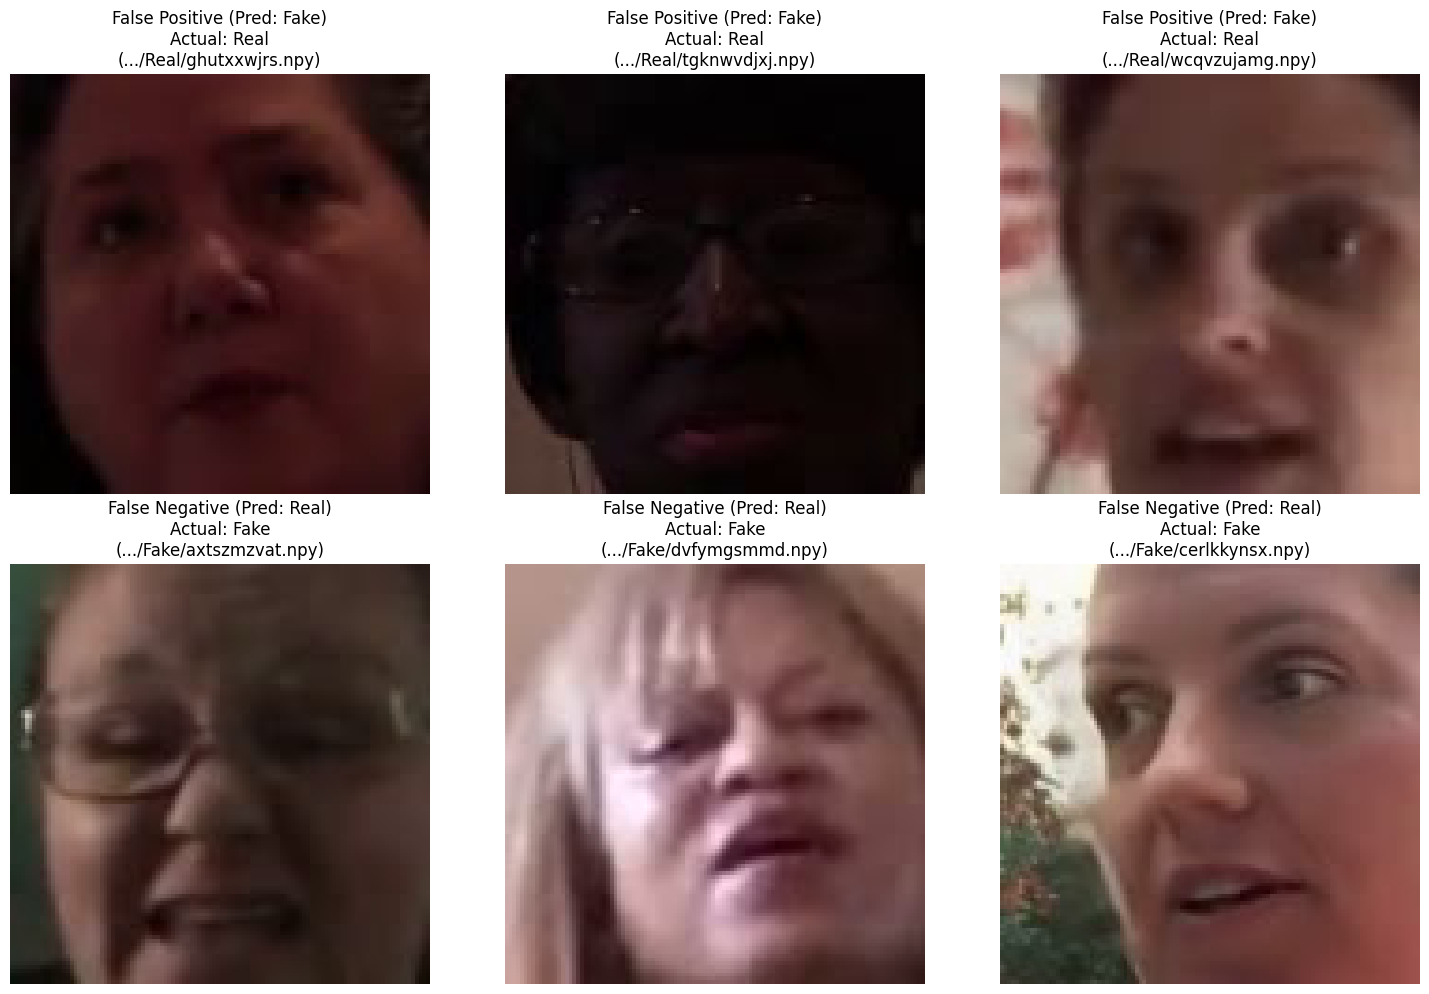

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure 'all_labels', 'all_preds', 'val_files' are available
if 'all_labels' in locals() and 'all_preds' in locals() and 'val_files' in locals():
    num_misclassified_to_show = 3 # Show up to 3 FP and 3 FN

    # Find indices of misclassifications
    misclassified_indices = np.where(all_labels != all_preds)[0]

    false_positive_indices = [i for i in misclassified_indices if all_labels[i] == 0] # Actual Real, Predicted Fake
    false_negative_indices = [i for i in misclassified_indices if all_labels[i] == 1] # Actual Fake, Predicted Real

    print(f"\nFound {len(false_positive_indices)} False Positives (Predicted Fake, Actual Real).")
    print(f"Found {len(false_negative_indices)} False Negatives (Predicted Real, Actual Fake).")

    plt.figure(figsize=(15, 10))
    plot_idx = 1

    # Display False Positives
    print("\nDisplaying sample False Positives...")
    indices_to_show = random.sample(false_positive_indices, min(num_misclassified_to_show, len(false_positive_indices)))
    for i in indices_to_show:
        npy_path = val_files[i] # Map index back to validation file list
        try:
            sequence = np.load(npy_path)
            frame_to_show = sequence[sequence.shape[0] // 2]
            # frame_to_show = (frame_to_show * 255).astype(np.uint8) # If normalized

            plt.subplot(2, num_misclassified_to_show, plot_idx)
            plt.imshow(frame_to_show)
            plt.title(f"False Positive (Pred: Fake)\nActual: Real\n(...{npy_path[-20:]})")
            plt.axis('off')
            plot_idx += 1
        except Exception as e:
             print(f"Could not load/plot {npy_path}: {e}")


    # Display False Negatives
    print("\nDisplaying sample False Negatives...")
    # Reset plot index for the second row (optional, adjust subplotting if needed)
    plot_idx = num_misclassified_to_show + 1
    indices_to_show = random.sample(false_negative_indices, min(num_misclassified_to_show, len(false_negative_indices)))
    for i in indices_to_show:
        npy_path = val_files[i] # Map index back to validation file list
        try:
            sequence = np.load(npy_path)
            frame_to_show = sequence[sequence.shape[0] // 2]
            # frame_to_show = (frame_to_show * 255).astype(np.uint8) # If normalized

            plt.subplot(2, num_misclassified_to_show, plot_idx)
            plt.imshow(frame_to_show)
            plt.title(f"False Negative (Pred: Real)\nActual: Fake\n(...{npy_path[-20:]})")
            plt.axis('off')
            plot_idx += 1
        except Exception as e:
             print(f"Could not load/plot {npy_path}: {e}")

    plt.tight_layout()
    plt.show()

else:
     print("Error: 'all_labels', 'all_preds', or 'val_files' not found.")

In [39]:
import os
import random
import time
from google.colab import files # For triggering downloads

# --- Configuration ---
VIDEO_DATA_DIR = './deepfake_data/DFDC_Dataset' # Original video location
NUM_TO_DOWNLOAD = 10 # How many Real videos to download

print("--- Downloading Unused REAL Videos ---")

# --- Ensure 'used_basenames' set is available ---
if 'used_basenames' not in locals() or not isinstance(used_basenames, set):
    print("Error: The 'used_basenames' set is not available.")
    print("Please re-run the relevant cells (from Phase 3, Sec 1 modified & Phase 7 setup)")
    print("that generated 'all_files' and then 'used_basenames'.")
else:
    print(f"Using the set of {len(used_basenames)} used basenames.")

    unused_real_videos = []
    possible_extensions = ('.mp4', '.avi', '.mov', '.mkv')

    # --- Find all unused Real videos ---
    real_dir_path = os.path.join(VIDEO_DATA_DIR, 'Real')
    if os.path.isdir(real_dir_path):
        print(f"Scanning {real_dir_path}...")
        for filename in os.listdir(real_dir_path):
            if filename.lower().endswith(possible_extensions):
                original_basename = os.path.splitext(filename)[0]
                if original_basename not in used_basenames:
                    unused_real_videos.append(os.path.join(real_dir_path, filename))
    else:
        print(f"Warning: Directory not found {real_dir_path}")

    print(f"\nFound {len(unused_real_videos)} unused Real videos.")

    # --- Select random Real videos to download ---
    real_videos_to_download = []
    if unused_real_videos:
        num_real = min(NUM_TO_DOWNLOAD, len(unused_real_videos))
        real_videos_to_download = random.sample(unused_real_videos, num_real)
        print(f"Selected {num_real} Real videos for download.")
    else:
        print("No unused Real videos found to select.")

    # --- Trigger downloads for Real videos ---
    if real_videos_to_download:
        print(f"\nStarting downloads for {len(real_videos_to_download)} REAL videos...")
        print("Your browser will prompt you to save each file.")
        for video_path in real_videos_to_download:
            try:
                print(f"  Downloading {os.path.basename(video_path)}...")
                files.download(video_path)
                time.sleep(1) # Small delay
            except Exception as e:
                print(f"    Error downloading {video_path}: {e}")
        print("\nDownload process initiated for selected REAL files.")
    else:
        print("\nNo REAL videos selected for download.")

--- Downloading Unused REAL Videos ---
Using the set of 1200 used basenames.
Scanning ./deepfake_data/DFDC_Dataset/Real...

Found 1127 unused Real videos.
Selected 10 Real videos for download.

Starting downloads for 10 REAL videos...
Your browser will prompt you to save each file.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (12 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download process initiated for selected REAL files.


In [40]:
import os
import random
import time
from google.colab import files # For triggering downloads

# --- Configuration ---
VIDEO_DATA_DIR = './deepfake_data/DFDC_Dataset' # Original video location
NUM_TO_DOWNLOAD = 10 # How many Fake videos to download

print("\n--- Downloading Unused FAKE Videos ---")

# --- Ensure 'used_basenames' set is available ---
if 'used_basenames' not in locals() or not isinstance(used_basenames, set):
    print("Error: The 'used_basenames' set is not available.")
    print("Please re-run the relevant cells (from Phase 3, Sec 1 modified & Phase 7 setup)")
    print("that generated 'all_files' and then 'used_basenames'.")
else:
    print(f"Using the set of {len(used_basenames)} used basenames.")

    unused_fake_videos = []
    possible_extensions = ('.mp4', '.avi', '.mov', '.mkv')

    # --- Find all unused Fake videos ---
    fake_dir_path = os.path.join(VIDEO_DATA_DIR, 'Fake')
    if os.path.isdir(fake_dir_path):
        print(f"Scanning {fake_dir_path}...")
        for filename in os.listdir(fake_dir_path):
            if filename.lower().endswith(possible_extensions):
                original_basename = os.path.splitext(filename)[0]
                if original_basename not in used_basenames:
                    unused_fake_videos.append(os.path.join(fake_dir_path, filename))
    else:
        print(f"Warning: Directory not found {fake_dir_path}")

    print(f"\nFound {len(unused_fake_videos)} unused Fake videos.")

    # --- Select random Fake videos to download ---
    fake_videos_to_download = []
    if unused_fake_videos:
        num_fake = min(NUM_TO_DOWNLOAD, len(unused_fake_videos))
        fake_videos_to_download = random.sample(unused_fake_videos, num_fake)
        print(f"Selected {num_fake} Fake videos for download.")
    else:
        print("No unused Fake videos found to select.")

    # --- Trigger downloads for Fake videos ---
    if fake_videos_to_download:
        print(f"\nStarting downloads for {len(fake_videos_to_download)} FAKE videos...")
        print("Your browser will prompt you to save each file.")
        for video_path in fake_videos_to_download:
            try:
                print(f"  Downloading {os.path.basename(video_path)}...")
                files.download(video_path)
                time.sleep(1) # Small delay
            except Exception as e:
                print(f"    Error downloading {video_path}: {e}")
        print("\nDownload process initiated for selected FAKE files.")
    else:
        print("\nNo FAKE videos selected for download.")


--- Downloading Unused FAKE Videos ---
Using the set of 1200 used basenames.
Scanning ./deepfake_data/DFDC_Dataset/Fake...

Found 966 unused Fake videos.
Selected 10 Fake videos for download.

Starting downloads for 10 FAKE videos...
Your browser will prompt you to save each file.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (12 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download process initiated for selected FAKE files.
